# exploration des données dpe

échantillon de 300 000 logements au hasard, téléchargé avec `scripts/download_data.py`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_parquet("../data/dpe_sample.parquet")
df.shape

(300000, 21)

## 1. combien de logements par classe ?

etiquette_dpe
A     1.5
B     5.1
C    36.8
D    31.0
E    15.8
F     6.3
G     3.5
Name: proportion, dtype: float64

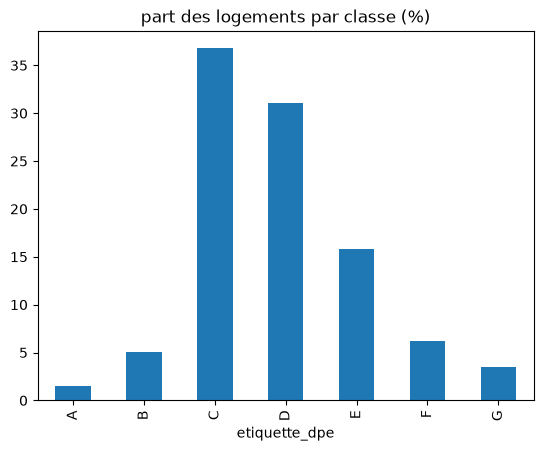

In [2]:
part = df["etiquette_dpe"].value_counts(normalize=True).sort_index() * 100
part.plot.bar(title="part des logements par classe (%)")
part.round(1)

## 2. quelles colonnes sont vides, et à quel point ? (missing values)

In [3]:
(df.isna().mean() * 100).round(1).sort_values(ascending=False)

typologie_logement                     96.5
position_logement_dans_immeuble        96.5
presence_production_pv                 93.2
numero_dpe_remplace                    90.9
type_generateur_chauffage_principal    69.2
annee_construction                     41.7
type_installation_chauffage            29.9
numero_etage_appartement               16.2
code_departement_ban                    3.5
nombre_niveau_logement                  2.7
surface_habitable_logement              2.6
classe_altitude                         0.2
zone_climatique                         0.2
etiquette_dpe                           0.0
date_etablissement_dpe                  0.0
numero_dpe                              0.0
type_energie_principale_chauffage       0.0
type_batiment                           0.0
periode_construction                    0.0
type_energie_principale_ecs             0.0
hauteur_sous_plafond                    0.0
dtype: float64

## 3. quelles valeurs sont absurdes ?

In [4]:
print("surface < 9 m² :", (df["surface_habitable_logement"] < 9).sum())
print("surface > 500 m² :", (df["surface_habitable_logement"] > 500).sum())
print("année < 1700 :", (df["annee_construction"] < 1700).sum())
print("année > 2026 :", (df["annee_construction"] > 2026).sum())
print("hauteur < 2,2 m :", (df["hauteur_sous_plafond"] < 2.2).sum())
print("hauteur > 5 m :", (df["hauteur_sous_plafond"] > 5).sum())
df[["surface_habitable_logement", "annee_construction", "hauteur_sous_plafond", "nombre_niveau_logement"]].describe().round(1)

surface < 9 m² : 221
surface > 500 m² : 149
année < 1700 : 95
année > 2026 : 5
hauteur < 2,2 m : 1097
hauteur > 5 m : 252


,surface_habitable_logement,annee_construction,hauteur_sous_plafond,nombre_niveau_logement
count,292194.0,174821.0,300000.0,291969.0
mean,72.9,1972.1,2.6,1.4
std,51.1,34.3,4.1,5.5
min,3.0,1400.0,0.2,1.0
25%,46.6,1953.0,2.5,1.0
50%,66.0,1974.0,2.5,1.0
75%,86.8,1997.0,2.5,1.0
max,9497.3,2063.0,1971.0,2015.0


## 4. dates des dpe : avant ou après la nouvelle règle de 2026 ?

après le 1er janvier 2026 : 43783


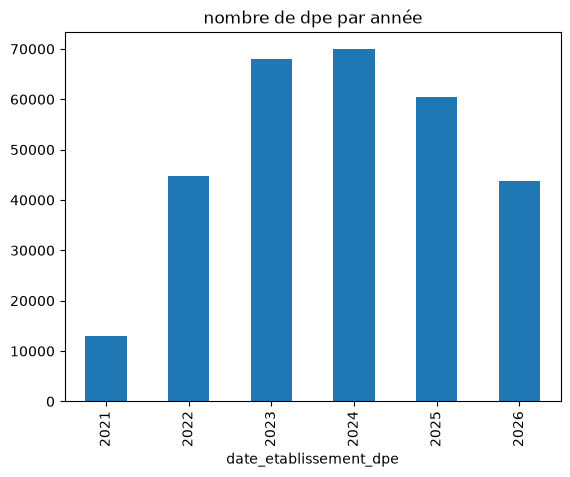

In [5]:
date = pd.to_datetime(df["date_etablissement_dpe"])
date.dt.year.value_counts().sort_index().plot.bar(title="nombre de dpe par année")
print("après le 1er janvier 2026 :", (date >= "2026-01-01").sum())

## 5. combien de logements par département ?

In [6]:
par_dep = df["code_departement_ban"].value_counts()
print("nombre de départements :", par_dep.size)
par_dep.head(10)

nombre de départements : 100


code_departement_ban
75    16159
59    11495
69     9825
92     9559
13     9096
93     7826
94     7684
33     7574
44     6774
76     6708
Name: count, dtype: int64

## 6. quels liens avec la classe ?

une passoire = classe f ou g.

<Axes: title={'center': 'part de passoires selon la période de construction (%)'}, xlabel='periode_construction'>

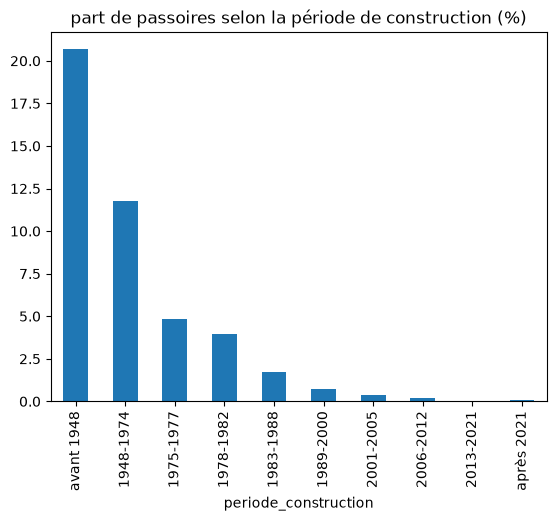

In [7]:
df["passoire"] = df["etiquette_dpe"].isin(["F", "G"])

ordre = ["avant 1948", "1948-1974", "1975-1977", "1978-1982", "1983-1988",
         "1989-2000", "2001-2005", "2006-2012", "2013-2021", "après 2021"]
(df.groupby("periode_construction")["passoire"].mean() * 100).reindex(ordre).plot.bar(
    title="part de passoires selon la période de construction (%)")

<Axes: title={'center': "part de passoires selon l'énergie de chauffage (%)"}, ylabel='type_energie_principale_chauffage'>

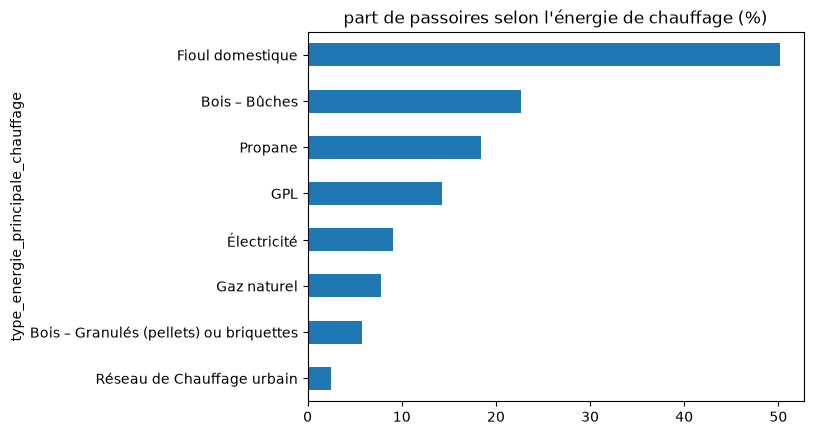

In [8]:
energies = df["type_energie_principale_chauffage"].value_counts().head(8).index
(df[df["type_energie_principale_chauffage"].isin(energies)]
   .groupby("type_energie_principale_chauffage")["passoire"].mean() * 100
).sort_values().plot.barh(title="part de passoires selon l'énergie de chauffage (%)")

In [9]:
(df.groupby("type_batiment")["passoire"].mean() * 100).round(0)

type_batiment
appartement     7.0
immeuble        9.0
maison         16.0
Name: passoire, dtype: float64